## CO2.2 – Final Project: RF-DETR Pedestrian Detection

###Dataset Preparation

 The initial step connects Google Colab to Google Drive and identifies the existing dataset files to avoid unnecessary downloads or reconstruction.

### 1.1 Google Drive Connection and Dataset Location

This step mounts Google Drive to allow the notebook to access the pedestrian detection dataset created in previous activities. It also displays the main Google Drive folders so that the existing dataset can be located and reused without downloading or preprocessing the images again.

In [1]:
# CODE CELL 1: CONNECT GOOGLE DRIVE AND INSPECT FOLDERS

# Import the Google Drive integration provided by Google Colab.
# This allows the notebook to access files stored in the user's Google Drive account.
from google.colab import drive

# Mount Google Drive inside the Colab runtime.
# This provides access to the existing pedestrian detection dataset and project files.
drive.mount("/content/drive")

# Import the Path class from Python's pathlib module.
# This allows folders and file paths to be handled consistently throughout the project.
from pathlib import Path

# Define the root directory of the user's Google Drive.
# This directory will be used to locate the dataset from the previous computer vision activities.
DRIVE_ROOT = Path("/content/drive/MyDrive")

# Display a heading to identify the directory inspection results.
# This makes it easier to distinguish the folder listing from other notebook outputs.
print("CO2.2 - GOOGLE DRIVE FOLDER INSPECTION")
print("=" * 60)

# Iterate through the main folders and files stored in Google Drive.
# This helps identify the directory containing the CO1.1–CO1.4 pedestrian detection dataset.
for item in sorted(DRIVE_ROOT.iterdir()):
    print("[FOLDER]" if item.is_dir() else "[FILE]", item.name)

Mounted at /content/drive
CO2.2 - GOOGLE DRIVE FOLDER INSPECTION
[FOLDER] CO1_1_Pedestrian_Detection
[FOLDER] Colab Notebooks
[FOLDER] SA2 Deliverables
[FILE] SA2_YOLO26_Vehicle_Deliverables.zip
[FOLDER] SA2_YOLO26_Vehicle_Runs
[FOLDER] Vehicle_Classification_Project
[FOLDER] content
[FOLDER] vehicle project
[FOLDER] web


### 1.2 Existing Dataset Directory Inspection

This step examines the existing CO1.1 pedestrian detection project directory to locate the image dataset, annotation files, and training-related folders. Identifying these resources is necessary to reuse the original preprocessed dataset and determine whether additional preparation is required for RF-DETR training.

In [2]:
# CODE CELL 2: INSPECT EXISTING PEDESTRIAN DATASET

# Define the directory containing the original CO1.1 pedestrian detection project.
# This reuses the Google Drive location identified during the initial folder inspection.
DATASET_ROOT = DRIVE_ROOT / "CO1_1_Pedestrian_Detection"

# Display the directory being examined and whether it exists.
# This confirms that the project files can be accessed before dataset preparation begins.
print("CO2.2 - EXISTING PEDESTRIAN DATASET INSPECTION")
print("=" * 65)
print("Dataset directory:", DATASET_ROOT)
print("Directory exists:", DATASET_ROOT.exists())

# Define the maximum folder depth and the maximum number of displayed entries.
# These limits prevent excessively long outputs while preserving a useful overview of the dataset structure.
MAX_DEPTH = 4
MAX_ENTRIES = 150

# Check whether the previously identified project directory is available.
# The inspection proceeds only when Google Drive contains the expected folder.
if DATASET_ROOT.is_dir():

    # Initialize a counter for displayed entries.
    # This counter ensures that the inspection output remains manageable.
    displayed_entries = 0

    # Walk through the directory tree in alphabetical order.
    # This reveals the organization of images, annotations, datasets, and model-related folders.
    for item in sorted(DATASET_ROOT.rglob("*")):

        # Calculate the depth of each item relative to the project directory.
        # This allows deeply nested files to be excluded from the initial inspection.
        relative_path = item.relative_to(DATASET_ROOT)
        depth = len(relative_path.parts)

        # Display only items within the permitted inspection depth.
        # This provides a readable overview without printing every image or annotation file.
        if depth <= MAX_DEPTH:

            # Identify whether the current entry is a folder or a file.
            # This distinction makes the dataset directory structure easier to understand.
            entry_type = "[FOLDER]" if item.is_dir() else "[FILE]"

            # Print the entry using indentation based on its directory depth.
            # This makes nested dataset folders visually distinguishable.
            print("  " * (depth - 1) + entry_type, item.name)

            # Update the number of displayed entries.
            # This tracks when the configured output limit has been reached.
            displayed_entries += 1

            # Stop listing files after reaching the maximum number of entries.
            # This prevents large image datasets from overwhelming the Colab output.
            if displayed_entries >= MAX_ENTRIES:
                print("Output limit reached. Additional entries are not displayed.")
                break

# Handle the case where the expected project directory is unavailable.
# This helps identify incorrect folder names or Google Drive mounting problems.
else:
    print("The pedestrian detection project folder was not found.")

CO2.2 - EXISTING PEDESTRIAN DATASET INSPECTION
Dataset directory: /content/drive/MyDrive/CO1_1_Pedestrian_Detection
Directory exists: True
[FILE] CO1_1_Low_Light_Pedestrian_Detection.v1-original_pedestrian_annotations_v1.yolov8.zip
[FOLDER] CO1_3_Ground_Truth
  [FILE] annotation_corrections.csv
  [FILE] automated_correction_suggestions.csv
  [FOLDER] corrected_test_labels
    [FILE] video01_frame0023940_jpg.rf.587c0554a2a4afa83567bca08b3e87ce_mild.txt
    [FILE] video01_frame0023940_jpg.rf.587c0554a2a4afa83567bca08b3e87ce_moderate.txt
    [FILE] video01_frame0023940_jpg.rf.587c0554a2a4afa83567bca08b3e87ce_severe.txt
    [FILE] video01_frame0023970_jpg.rf.5c6be73f62834ca5a6cdcd9532bbba18_mild.txt
    [FILE] video01_frame0023970_jpg.rf.5c6be73f62834ca5a6cdcd9532bbba18_moderate.txt
    [FILE] video01_frame0023970_jpg.rf.5c6be73f62834ca5a6cdcd9532bbba18_severe.txt
    [FILE] video01_frame0024000_jpg.rf.64e628c07014c619d53cb010086fd48b_mild.txt
    [FILE] video01_frame0024000_jpg.rf.64e628c

### 1.3 Dataset Structure Identification

This step identifies the main directories and dataset configuration files within the existing pedestrian detection project. The inspection focuses on locating training, validation, and testing datasets, annotation formats, and compressed dataset archives to determine which existing resources are suitable for RF-DETR training.

In [3]:
# CODE CELL 3: IDENTIFY DATASET STRUCTURE

# Display a heading for the dataset structure inspection.
# This separates the results from previous notebook outputs and identifies the purpose of the inspection.
print("CO2.2 - DATASET STRUCTURE IDENTIFICATION")
print("=" * 65)

# Display the immediate subfolders within the existing pedestrian detection project.
# These folders may contain the original images, preprocessed datasets, or results from previous activities.
print("\nMAIN PROJECT FOLDERS:")

# Iterate through the first directory level of the existing project.
# Only directory names are displayed to avoid listing thousands of image and annotation files.
for folder in sorted(DATASET_ROOT.iterdir()):
    if folder.is_dir():
        print("[FOLDER]", folder.name)

# Define the dataset-related filenames and directory names to locate.
# These names commonly identify training splits, annotations, and dataset configuration files.
TARGET_NAMES = {
    "train", "valid", "val", "test",
    "images", "labels", "annotations",
    "data.yaml", "dataset.yaml",
    "_annotations.coco.json"
}

# Create a list to store matching dataset folders and configuration files.
# This allows the results to be displayed together after scanning the project.
dataset_matches = []

# Inspect the existing project directory for dataset-related resources.
# The search records matching folders, configuration files, and compressed dataset archives.
for item in DATASET_ROOT.rglob("*"):

    # Determine whether the current item matches a commonly used dataset name or archive extension.
    # Matching files may help identify which dataset format was exported from Roboflow.
    if item.name.lower() in TARGET_NAMES or (
        item.is_file() and item.suffix.lower() == ".zip"
    ):
        dataset_matches.append(item)

# Display the detected dataset locations using paths relative to the project root.
# Relative paths are easier to read and can help identify the correct dataset for RF-DETR.
print("\nDATASET-RELATED FOLDERS AND FILES:")

# Print up to 100 matching entries from the project.
# This avoids excessive output while still revealing the main dataset structure.
for item in sorted(dataset_matches)[:100]:
    print("[FOLDER]" if item.is_dir() else "[FILE]",
          item.relative_to(DATASET_ROOT))

# Display the total number of matches found during the inspection.
# This indicates whether additional dataset locations exist beyond the displayed results.
print("\nTotal matching entries:", len(dataset_matches))

CO2.2 - DATASET STRUCTURE IDENTIFICATION

MAIN PROJECT FOLDERS:
[FOLDER] CO1_3_Ground_Truth
[FOLDER] CO1_4_DeepSORT
[FOLDER] chronological_dataset
[FOLDER] evaluation_results
[FOLDER] lighting_level_evaluation
[FOLDER] lli_comparisons
[FOLDER] lli_pedestrian_dataset
[FOLDER] original_images
[FOLDER] prediction_results
[FOLDER] preprocessed_images
[FOLDER] roboflow_annotated_dataset
[FOLDER] training_results
[FOLDER] videos

DATASET-RELATED FOLDERS AND FILES:
[FILE] CO1_1_Low_Light_Pedestrian_Detection.v1-original_pedestrian_annotations_v1.yolov8.zip
[FOLDER] chronological_dataset/test
[FOLDER] chronological_dataset/test/images
[FOLDER] chronological_dataset/test/labels
[FOLDER] chronological_dataset/train
[FOLDER] chronological_dataset/train/images
[FOLDER] chronological_dataset/train/labels
[FOLDER] chronological_dataset/valid
[FOLDER] chronological_dataset/valid/images
[FOLDER] chronological_dataset/valid/labels
[FILE] lighting_level_evaluation/mild/data.yaml
[FOLDER] lighting_level_

### 1.4 Dataset Comparison and Verification

This step compares the existing pedestrian detection datasets by counting images and annotation files in their training, validation, and test splits. It also examines the dataset configuration files to verify the available object classes and determine which dataset can be reused for RF-DETR training without unnecessary reprocessing or annotation conversion.

In [4]:
# CODE CELL 4: COMPARE DATASET COUNTS AND CLASSES

# Import the YAML library to examine existing dataset configuration files.
# This allows us to verify the class definitions without modifying the datasets.
import yaml

# Define the three existing pedestrian detection datasets identified in Code Cell 3.
# These are the candidates for RF-DETR training using previously prepared images and labels.
CANDIDATE_DATASETS = [
    "chronological_dataset",
    "lli_pedestrian_dataset",
    "roboflow_annotated_dataset"
]

# Define the image formats recognized during dataset inspection.
# These extensions help count images consistently across all dataset splits.
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Display the heading for the dataset comparison.
# This identifies the dataset statistics that will be used during dataset selection.
print("CO2.2 - DATASET COMPARISON")
print("=" * 70)

# Examine each existing dataset separately.
# This makes it possible to compare their training, validation, and testing resources.
for dataset_name in CANDIDATE_DATASETS:

    # Construct the complete path to the current candidate dataset.
    # This uses the existing project directory without copying or changing its contents.
    dataset_path = DATASET_ROOT / dataset_name

    # Display the dataset name and corresponding Google Drive location.
    # This keeps the comparison results organized by dataset.
    print(f"\nDATASET: {dataset_name}")
    print("Path:", dataset_path)

    # Initialize a dictionary to record image counts for all three splits.
    # These counts will be used to calculate the dataset splitting percentages.
    split_counts = {}

    # Inspect the training, validation, and testing subsets.
    # Each subset should have images and matching annotation files for supervised detection.
    for split in ["train", "valid", "test"]:

        # Define the image and annotation directories for the current split.
        # These paths follow the YOLO dataset structure found during Code Cell 3.
        images_dir = dataset_path / split / "images"
        labels_dir = dataset_path / split / "labels"

        # Count the image files stored in the current split.
        # The count excludes non-image files that may be present in the directory.
        image_count = (
            sum(1 for file in images_dir.iterdir()
                if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS)
            if images_dir.is_dir() else 0
        )

        # Count the YOLO text annotation files stored in the current split.
        # This helps identify whether bounding-box annotation files are available.
        label_count = (
            sum(1 for file in labels_dir.iterdir()
                if file.is_file() and file.suffix.lower() == ".txt")
            if labels_dir.is_dir() else 0
        )

        # Store the image count for later calculation of the splitting percentage.
        # This avoids scanning the same directory again when reporting dataset proportions.
        split_counts[split] = image_count

        # Display the image and annotation counts for the current split.
        # The results help reveal incomplete or unexpectedly small subsets.
        print(f"{split.upper():5s} | Images: {image_count:5d} | Labels: {label_count:5d}")

    # Calculate the total number of images across the three dataset splits.
    # This provides a basis for comparing the sizes of the existing datasets.
    total_images = sum(split_counts.values())

    # Display the image distribution when the dataset contains images.
    # The percentages reveal whether the existing split ratio is suitable for the project.
    if total_images > 0:
        print("Total images:", total_images)
        for split, count in split_counts.items():
            print(f"{split.capitalize()} percentage: {count / total_images * 100:.2f}%")

    # Define the expected location of the YOLO dataset configuration file.
    # The configuration contains class information needed for RF-DETR training.
    yaml_path = dataset_path / "data.yaml"

    # Read the YAML configuration only when the file exists.
    # This prevents errors for candidate datasets without configuration files.
    if yaml_path.is_file():

        # Open and parse the existing dataset configuration.
        # Safe YAML loading reads the stored configuration without executing arbitrary code.
        with open(yaml_path, "r", encoding="utf-8") as file:
            dataset_config = yaml.safe_load(file) or {}

        # Display the number of object classes and their names.
        # This verifies whether the dataset is restricted to pedestrian detection.
        print("Number of classes:", dataset_config.get("nc", "Not specified"))
        print("Class names:", dataset_config.get("names", "Not specified"))

    # Report when the candidate dataset does not have a YAML configuration.
    # We can address this later if the dataset is selected for RF-DETR training.
    else:
        print("Dataset YAML: Not found")

    # Display a separator to distinguish the results of different datasets.
    # This makes the final comparison easier to review.
    print("-" * 70)

CO2.2 - DATASET COMPARISON

DATASET: chronological_dataset
Path: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/chronological_dataset
TRAIN | Images:   639 | Labels:   639
VALID | Images:   119 | Labels:   119
TEST  | Images:   130 | Labels:   130
Total images: 888
Train percentage: 71.96%
Valid percentage: 13.40%
Test percentage: 14.64%
Dataset YAML: Not found
----------------------------------------------------------------------

DATASET: lli_pedestrian_dataset
Path: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/lli_pedestrian_dataset
TRAIN | Images:  1917 | Labels:  1917
VALID | Images:   357 | Labels:   357
TEST  | Images:   390 | Labels:   390
Total images: 2664
Train percentage: 71.96%
Valid percentage: 13.40%
Test percentage: 14.64%
Number of classes: 1
Class names: {0: 'person'}
----------------------------------------------------------------------

DATASET: roboflow_annotated_dataset
Path: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/roboflow_annotated_dataset
TRAI

### 1.5 Chronological Dataset Annotation Validation

This step validates the existing chronological pedestrian detection dataset before using it for RF-DETR training. The validation examines image-to-annotation correspondence, class identifiers, and normalized bounding-box coordinates across the training, validation, and test subsets. The results will determine whether the dataset is suitable for reuse without additional annotation processing.

In [5]:
# CODE CELL 5: VALIDATE CHRONOLOGICAL DATASET ANNOTATIONS

# Import Counter to summarize the annotation classes and potential errors.
# This makes it possible to verify the dataset without printing thousands of individual annotations.
from collections import Counter

# Define the chronological dataset identified during the previous comparison.
# This dataset is currently the preferred candidate for RF-DETR training.
CHRONOLOGICAL_DIR = DATASET_ROOT / "chronological_dataset"

# Create counters to store detected class IDs and annotation errors.
# These counters help identify whether the dataset follows the expected single-class YOLO format.
class_counts = Counter()
annotation_errors = Counter()

# Display the heading for the dataset annotation validation.
# This identifies the output as a verification step rather than a training operation.
print("CO2.2 - CHRONOLOGICAL DATASET ANNOTATION VALIDATION")
print("=" * 70)

# Examine each existing dataset split separately.
# Validating all three subsets ensures the same annotation format is used throughout the project.
for split in ["train", "valid", "test"]:

    # Define the corresponding image and annotation folders.
    # These paths refer to the existing files and do not modify the original dataset.
    images_dir = CHRONOLOGICAL_DIR / split / "images"
    labels_dir = CHRONOLOGICAL_DIR / split / "labels"

    # Collect image files and annotation files from the current subset.
    # Filename stems are used to verify the correspondence between images and bounding-box labels.
    image_files = {
        file.stem: file for file in images_dir.iterdir()
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    }
    label_files = {
        file.stem: file for file in labels_dir.glob("*.txt")
    }

    # Identify missing labels and annotation files without corresponding images.
    # These checks help detect incomplete datasets before model training begins.
    missing_labels = set(image_files) - set(label_files)
    extra_labels = set(label_files) - set(image_files)

    # Initialize counters for valid bounding boxes and empty annotation files.
    # Empty labels can represent background images, while valid boxes represent annotated objects.
    valid_boxes = 0
    empty_labels = 0

    # Read each annotation file and examine its contents.
    # YOLO detection annotations should contain a class ID and four normalized bounding-box values.
    for label_path in label_files.values():

        # Read nonempty lines from the annotation file.
        # Each nonempty line is expected to represent one annotated pedestrian.
        lines = [
            line.strip() for line in label_path.read_text(encoding="utf-8").splitlines()
            if line.strip()
        ]

        # Count annotation files that contain no object labels.
        # Such files are recorded for inspection but are not automatically considered invalid.
        if not lines:
            empty_labels += 1

        # Validate each annotated bounding box individually.
        # This identifies incorrect class IDs, malformed values, and invalid normalized coordinates.
        for line in lines:

            # Separate the values and verify the expected YOLO annotation length.
            # Standard object detection labels should contain exactly five values per bounding box.
            parts = line.split()
            if len(parts) != 5:
                annotation_errors["Invalid number of values"] += 1
                continue

            # Attempt to convert the annotation values into numerical coordinates.
            # Conversion errors indicate malformed labels that could interrupt model training.
            try:
                class_value, x, y, w, h = map(float, parts)
            except ValueError:
                annotation_errors["Non-numeric annotation"] += 1
                continue

            # Verify that the class identifier is a nonnegative integer.
            # For the intended pedestrian-only dataset, the expected class identifier is zero.
            if not class_value.is_integer() or class_value != 0:
                annotation_errors["Unexpected class ID"] += 1
                continue

            # Verify that coordinates are finite and normalized within image boundaries.
            # Width and height must be positive, and the bounding box must remain inside the image.
            if not (
                all(map(lambda v: v == v and abs(v) != float("inf"), [x, y, w, h]))
                and 0 <= x <= 1 and 0 <= y <= 1
                and 0 < w <= 1 and 0 < h <= 1
                and x - w / 2 >= -1e-5
                and y - h / 2 >= -1e-5
                and x + w / 2 <= 1 + 1e-5
                and y + h / 2 <= 1 + 1e-5
            ):
                annotation_errors["Invalid bounding-box coordinates"] += 1
                continue

            # Record the validated class identifier and bounding box.
            # These counts will confirm how many pedestrian instances are available for training and evaluation.
            class_counts[int(class_value)] += 1
            valid_boxes += 1

    # Display the annotation validation summary for the current dataset split.
    # The summary allows dataset quality to be assessed without listing individual image files.
    print(f"\n{split.upper()} SPLIT")
    print("Images:", len(image_files))
    print("Annotation files:", len(label_files))
    print("Missing annotation files:", len(missing_labels))
    print("Annotations without images:", len(extra_labels))
    print("Empty annotation files:", empty_labels)
    print("Valid pedestrian bounding boxes:", valid_boxes)

# Display the final class distribution and annotation errors.
# These results determine whether the dataset is ready for RF-DETR configuration.
print("\nFINAL ANNOTATION SUMMARY")
print("Class distribution:", dict(class_counts))
print("Annotation errors:", dict(annotation_errors))
print("=" * 70)

CO2.2 - CHRONOLOGICAL DATASET ANNOTATION VALIDATION

TRAIN SPLIT
Images: 639
Annotation files: 639
Missing annotation files: 0
Annotations without images: 0
Empty annotation files: 1
Valid pedestrian bounding boxes: 3303

VALID SPLIT
Images: 119
Annotation files: 119
Missing annotation files: 0
Annotations without images: 0
Empty annotation files: 1
Valid pedestrian bounding boxes: 467

TEST SPLIT
Images: 130
Annotation files: 130
Missing annotation files: 0
Annotations without images: 0
Empty annotation files: 1
Valid pedestrian bounding boxes: 596

FINAL ANNOTATION SUMMARY
Class distribution: {0: 4366}
Annotation errors: {}


### 1.6 Dataset Split Integrity Verification

This step checks the training, validation, and testing subsets for overlapping image filenames and examines sample filenames to understand the dataset organization. The verification helps identify possible duplication between dataset subsets before RF-DETR training and evaluation. This is especially important because the pedestrian detection images were extracted from video recordings.

In [6]:
# CODE CELL 6: VERIFY DATASET SPLIT INTEGRITY

# Import combinations to compare each pair of dataset subsets.
# This allows us to check train-validation, train-test, and validation-test separately.
from itertools import combinations

# Create a dictionary to store image filenames from each dataset split.
# Filename stems are collected to identify images that may appear in multiple subsets.
split_filenames = {}

# Display the heading for the dataset integrity inspection.
# This separates the current results from the previous annotation validation.
print("CO2.2 - DATASET SPLIT INTEGRITY VERIFICATION")
print("=" * 70)

# Inspect the training, validation, and testing image directories.
# All files are read from the existing chronological dataset without modifying them.
for split in ["train", "valid", "test"]:

    # Construct the location of the current split's image directory.
    # This uses the chronological dataset selected during the earlier inspection.
    images_dir = CHRONOLOGICAL_DIR / split / "images"

    # Collect the filename stems of all recognized image files.
    # This makes it possible to identify repeated filenames even when image extensions differ.
    filenames = sorted(
        file.stem for file in images_dir.iterdir()
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    )

    # Store the collected filenames for comparison with other dataset splits.
    # Keeping these values in memory avoids changing or copying the original images.
    split_filenames[split] = set(filenames)

    # Display the image count and a small sample of filenames.
    # The examples help determine whether images are identified by video and frame number.
    print(f"\n{split.upper()} SPLIT")
    print("Total images:", len(filenames))
    print("Sample filenames:", filenames[:5])

# Compare filename overlaps between every pair of dataset splits.
# Repeated filenames may indicate accidental reuse of the same images.
print("\nCROSS-SPLIT FILENAME OVERLAP")

# Generate the three possible pairs of training, validation, and testing subsets.
# Each comparison checks whether the same filename stem appears in both subsets.
for split_a, split_b in combinations(["train", "valid", "test"], 2):

    # Determine the intersection between the two sets of image filenames.
    # The intersection contains filename stems that appear in both dataset splits.
    overlapping = split_filenames[split_a] & split_filenames[split_b]

    # Display the number of repeated filenames between the selected subsets.
    # Zero overlaps is a positive result, although it does not rule out visually similar frames.
    print(f"{split_a.upper()} vs {split_b.upper()}: {len(overlapping)} overlapping filenames")

    # Display a small sample only when repeated filenames are detected.
    # This provides useful evidence for deciding whether further investigation is required.
    if overlapping:
        print("Examples:", sorted(overlapping)[:5])

# Display the final summary of the filename integrity inspection.
# This marks the completion of the initial comparison without modifying dataset contents.
print("\nFilename overlap inspection completed.")
print("Note: This does not detect identical images saved under different filenames.")

CO2.2 - DATASET SPLIT INTEGRITY VERIFICATION

TRAIN SPLIT
Total images: 639
Sample filenames: ['video01_frame0000000_jpg.rf.4e5b5337ff163c643fcd7e54f90c7da9', 'video01_frame0000030_jpg.rf.cd40faeae7292717f6b5c247ede852ae', 'video01_frame0000060_jpg.rf.b01c5ba02929f6d9888a73b86b615f5f', 'video01_frame0000090_jpg.rf.0c17aebe6532457eb24f8e50757440f9', 'video01_frame0000120_jpg.rf.a54af2573f1285c0f2a54b2358962d18']

VALID SPLIT
Total images: 119
Sample filenames: ['video01_frame0019770_jpg.rf.e6ca422493d5ccc0f5604e78bb9bc49a', 'video01_frame0019800_jpg.rf.c52de3bd5bd41df35f3b2c0f1b5a0372', 'video01_frame0019830_jpg.rf.a4fddf750b71add41f706acda187ff7f', 'video01_frame0019860_jpg.rf.da6181b9a43b4821cf5ffc9804081cac', 'video01_frame0019890_jpg.rf.9c85321a8d9bdcdda690b32969b04992']

TEST SPLIT
Total images: 130
Sample filenames: ['video01_frame0023940_jpg.rf.587c0554a2a4afa83567bca08b3e87ce', 'video01_frame0023970_jpg.rf.5c6be73f62834ca5a6cdcd9532bbba18', 'video01_frame0024000_jpg.rf.64e628c07

### 1.7 Ground-Truth Annotation Review

This step examines the corrected ground-truth annotations produced during CO1.3 and compares their filenames with the chronological dataset's test annotations. The inspection determines whether the corrections correspond to the selected evaluation images and whether they need to be incorporated before RF-DETR evaluation. No existing annotations are modified during this step.

In [7]:
# CODE CELL 7: REVIEW CO1.3 GROUND-TRUTH ANNOTATIONS

# Define the original test annotation directory and the CO1.3 corrected annotation directory.
# These locations contain the labels that must be compared before finalizing the RF-DETR evaluation dataset.
TEST_LABELS_DIR = CHRONOLOGICAL_DIR / "test" / "labels"
CORRECTED_LABELS_DIR = DATASET_ROOT / "CO1_3_Ground_Truth" / "corrected_test_labels"

# Display the heading and confirm the locations of both annotation directories.
# This ensures that the comparison examines the intended project files.
print("CO2.2 - CO1.3 GROUND-TRUTH ANNOTATION REVIEW")
print("=" * 70)
print("Original labels:", TEST_LABELS_DIR)
print("Corrected labels:", CORRECTED_LABELS_DIR)

# Collect the original test annotation files into a dictionary.
# Their filename stems will be used to find matching corrected annotations.
original_labels = {
    file.stem: file for file in TEST_LABELS_DIR.glob("*.txt")
}

# Collect the corrected annotation files into a list.
# This allows us to examine the lighting-specific correction variants separately.
corrected_labels = sorted(CORRECTED_LABELS_DIR.glob("*.txt"))

# Display the number of original and corrected annotation files.
# The counts indicate how much ground-truth correction material is available.
print("\nANNOTATION FILE COUNTS")
print("Original test labels:", len(original_labels))
print("Corrected annotation files:", len(corrected_labels))

# Define the known lighting suffixes used during the CO1.3 activity.
# These suffixes distinguish corrected annotations for mild, moderate, and severe lighting.
LIGHTING_SUFFIXES = ("_mild", "_moderate", "_severe")

# Initialize counters for lighting variants and matched annotations.
# These results will help establish whether corrections correspond to the chronological test set.
lighting_counts = Counter()
matched_counts = Counter()

# Examine each corrected annotation filename without changing its contents.
# Removing the lighting suffix allows it to be compared against the original image identifier.
for corrected_file in corrected_labels:

    # Identify the lighting suffix belonging to the corrected annotation.
    # Files without a recognized suffix are counted separately for investigation.
    lighting = next(
        (level for level in LIGHTING_SUFFIXES if corrected_file.stem.endswith(level)),
        None
    )

    # Calculate the original image identifier by removing only the final lighting suffix.
    # This preserves the Roboflow filename hash needed for accurate matching.
    original_stem = (
        corrected_file.stem[:-len(lighting)]
        if lighting else corrected_file.stem
    )

    # Record how many corrected files belong to each lighting variant.
    # These counts reveal whether the previous activity generated multiple corrections per image.
    lighting_name = lighting.lstrip("_") if lighting else "unrecognized"
    lighting_counts[lighting_name] += 1

    # Check whether the corrected file corresponds to an existing chronological test label.
    # Matching names alone do not establish whether annotation contents are identical.
    if original_stem in original_labels:
        matched_counts[lighting_name] += 1

# Display the number of corrected annotation files in each lighting category.
# This summarizes the CO1.3 materials without printing every annotation filename.
print("\nCORRECTED LABELS BY LIGHTING LEVEL")
for lighting_name, count in sorted(lighting_counts.items()):
    print(f"{lighting_name}: {count}")

# Display the number of corrected files matching original test image identifiers.
# These results indicate whether the CO1.3 corrections can potentially be used for evaluation.
print("\nMATCHES WITH CHRONOLOGICAL TEST SET")
for lighting_name, count in sorted(matched_counts.items()):
    print(f"{lighting_name}: {count}")

# Compare the contents of matched corrected annotations with their original labels.
# Differences are counted by lighting level without assuming which version is more accurate.
different_counts = Counter()
identical_counts = Counter()

# Examine every corrected file with a recognized original test counterpart.
# This identifies which correction variants differ from the existing test annotations.
for corrected_file in corrected_labels:

    # Identify the correction variant and reconstruct the original filename stem.
    # The method avoids confusing the lighting suffix with the original Roboflow identifier.
    lighting = next(
        (level for level in LIGHTING_SUFFIXES if corrected_file.stem.endswith(level)),
        None
    )
    original_stem = corrected_file.stem[:-len(lighting)] if lighting else corrected_file.stem

    # Skip corrected annotations that do not correspond to an original test label.
    # This prevents unrelated files from influencing the comparison.
    if original_stem not in original_labels:
        continue

    # Read and normalize both annotation files for a content comparison.
    # Removing surrounding whitespace prevents trivial formatting differences from being counted.
    original_text = original_labels[original_stem].read_text(encoding="utf-8").strip()
    corrected_text = corrected_file.read_text(encoding="utf-8").strip()

    # Count whether each corrected annotation is identical to or different from its original.
    # The results help determine whether the corrected annotations require further handling.
    lighting_name = lighting.lstrip("_") if lighting else "unrecognized"
    if original_text == corrected_text:
        identical_counts[lighting_name] += 1
    else:
        different_counts[lighting_name] += 1

# Display the final comparison of original and corrected annotation contents.
# This information will guide the next dataset preparation step without modifying any files.
print("\nANNOTATION CONTENT COMPARISON")
for lighting_name in sorted(lighting_counts):
    print(
        f"{lighting_name}: "
        f"Identical={identical_counts[lighting_name]}, "
        f"Different={different_counts[lighting_name]}"
    )

# Confirm that this operation was limited to reading and comparing existing files.
# The original dataset and CO1.3 corrections remain unchanged after the inspection.
print("\nReview completed. No dataset files were modified.")

CO2.2 - CO1.3 GROUND-TRUTH ANNOTATION REVIEW
Original labels: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/chronological_dataset/test/labels
Corrected labels: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/CO1_3_Ground_Truth/corrected_test_labels

ANNOTATION FILE COUNTS
Original test labels: 130
Corrected annotation files: 390

CORRECTED LABELS BY LIGHTING LEVEL
mild: 130
moderate: 130
severe: 130

MATCHES WITH CHRONOLOGICAL TEST SET
mild: 130
moderate: 130
severe: 130

ANNOTATION CONTENT COMPARISON
mild: Identical=50, Different=80
moderate: Identical=48, Different=82
severe: Identical=48, Different=82

Review completed. No dataset files were modified.


### 1.8 RF-DETR Dataset Configuration

This step creates the YAML configuration required to load the existing chronological pedestrian detection dataset into the RF-DETR framework. The configuration specifies the training, validation, and test image directories and defines the single object class as person. The existing images and bounding-box annotations are preserved without modification.

In [8]:
# CODE CELL 8: CREATE RF-DETR DATASET CONFIGURATION

# Define the location of the YAML configuration inside the selected dataset.
# RF-DETR uses this file to identify YOLO annotations and their corresponding image directories.
DATA_YAML_PATH = CHRONOLOGICAL_DIR / "data.yaml"

# Define the class information and relative paths for the dataset splits.
# The dataset contains one class called person, with training, validation, and testing directories already prepared.
dataset_configuration = {
    "names": ["person"],
    "nc": 1,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images"
}

# Check whether a dataset configuration already exists before writing a new file.
# This prevents the notebook from unintentionally replacing an existing configuration with different settings.
if DATA_YAML_PATH.exists():

    # Read the existing configuration and compare it with the intended settings.
    # The comparison ensures that an existing file is preserved unless it already matches our dataset requirements.
    with open(DATA_YAML_PATH, "r", encoding="utf-8") as file:
        existing_configuration = yaml.safe_load(file)

    # Display whether the existing configuration matches the intended dataset settings.
    # Any mismatch must be reviewed before proceeding to RF-DETR training.
    assert existing_configuration == dataset_configuration, (
        "An existing data.yaml has different settings. Review it before proceeding."
    )
    print("Existing configuration verified; no changes made.")

# Create the dataset configuration only when the file does not already exist.
# This adds the missing RF-DETR metadata without changing the images or annotations.
else:

    # Save the dataset settings as a YAML file in the dataset root directory.
    # The written configuration describes the existing single-class pedestrian detection dataset.
    with open(DATA_YAML_PATH, "w", encoding="utf-8") as file:
        yaml.safe_dump(dataset_configuration, file, sort_keys=False)

    # Confirm that the new configuration file was successfully created.
    # This indicates that the dataset metadata is ready for the RF-DETR loader.
    print("Dataset configuration created successfully.")

# Read the saved configuration to verify its actual contents.
# This confirms that the class name and split paths are available on Google Drive.
with open(DATA_YAML_PATH, "r", encoding="utf-8") as file:
    verified_configuration = yaml.safe_load(file)

# Display the configuration file location and its verified contents.
# These details can also be documented in the dataset preparation section of the final project report.
print("\nCO2.2 - RF-DETR DATASET CONFIGURATION")
print("=" * 65)
print("Configuration file:", DATA_YAML_PATH)
print("\nConfiguration contents:")
print(yaml.safe_dump(verified_configuration, sort_keys=False))

# Verify that every configured dataset split refers to an existing image directory.
# This helps prevent incorrect directory paths from interrupting RF-DETR training.
for split_key in ["train", "val", "test"]:

    # Construct the actual directory using the path stored in the YAML configuration.
    # Relative paths are resolved from the chronological dataset's root directory.
    split_directory = CHRONOLOGICAL_DIR / verified_configuration[split_key]

    # Confirm that the expected image directory exists.
    # An assertion error identifies a missing directory before model installation or training.
    assert split_directory.is_dir(), f"Missing dataset directory: {split_directory}"
    print(f"{split_key.upper()} directory verified:", split_directory)

# Display the final dataset configuration status.
# This confirms completion of the configuration step without modifying existing annotations.
print("\nRF-DETR dataset configuration: COMPLETE")

Dataset configuration created successfully.

CO2.2 - RF-DETR DATASET CONFIGURATION
Configuration file: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/chronological_dataset/data.yaml

Configuration contents:
names:
- person
nc: 1
train: train/images
val: valid/images
test: test/images

TRAIN directory verified: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/chronological_dataset/train/images
VAL directory verified: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/chronological_dataset/valid/images
TEST directory verified: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/chronological_dataset/test/images

RF-DETR dataset configuration: COMPLETE


### 2.1 GPU and PyTorch Environment Verification

This step verifies the availability of GPU acceleration in Google Colab and examines the installed PyTorch environment before implementing the RF-DETR object detection model. GPU availability is important because transformer-based object detection models require substantial computational resources during training. The inspection also records the Python, PyTorch, and CUDA versions to support reproducibility in the final project report.

In [9]:
# CODE CELL 9: VERIFY GPU AND PYTORCH ENVIRONMENT

# Import the platform module to identify the Python version used in Google Colab.
# Recording this information helps document the computational environment for the RF-DETR experiment.
import platform

# Import PyTorch, the deep learning framework used by the official RF-DETR implementation.
# PyTorch provides the tensor operations and GPU support needed for model training and evaluation.
import torch

# Display the heading for the RF-DETR computational environment inspection.
# This makes the environment details easy to identify in the notebook and final report.
print("CO2.2 - RF-DETR COMPUTATIONAL ENVIRONMENT")
print("=" * 65)

# Display the Python version used by the active Google Colab runtime.
# This information helps identify software compatibility requirements and supports reproducibility.
print("Python Version:", platform.python_version())

# Display the installed version of the PyTorch deep learning framework.
# This verifies that PyTorch is available before installing the RF-DETR model package.
print("PyTorch Version:", torch.__version__)

# Display the CUDA version associated with the installed PyTorch build.
# This identifies the CUDA runtime used for GPU acceleration when available.
print("PyTorch CUDA Version:", torch.version.cuda)

# Check whether PyTorch can access a CUDA-compatible GPU.
# RF-DETR training is expected to run more efficiently when a supported GPU is available.
GPU_AVAILABLE = torch.cuda.is_available()

# Display the result of the CUDA GPU availability check.
# This determines whether we can proceed with GPU-based model training.
print("CUDA Available:", GPU_AVAILABLE)

# Examine GPU hardware information only when CUDA acceleration is available.
# This prevents errors when Google Colab is running without a compatible GPU.
if GPU_AVAILABLE:

    # Retrieve the name of the GPU assigned to the Google Colab runtime.
    # The GPU model is useful for documenting hardware specifications in the final report.
    GPU_NAME = torch.cuda.get_device_name(0)

    # Display the GPU model and its allocated device index.
    # This confirms which GPU will be used for the RF-DETR implementation.
    print("GPU Name:", GPU_NAME)
    print("GPU Device Index:", torch.cuda.current_device())

    # Retrieve the total memory capacity of the assigned GPU in bytes.
    # GPU memory capacity helps determine appropriate RF-DETR batch sizes during training.
    GPU_MEMORY = torch.cuda.get_device_properties(0).total_memory

    # Convert the GPU memory capacity from bytes into gibibytes.
    # This makes the available hardware memory easier to interpret.
    GPU_MEMORY_GB = GPU_MEMORY / (1024 ** 3)

    # Display the calculated GPU memory capacity.
    # We will use this information when selecting resource-appropriate training settings.
    print(f"Total GPU Memory: {GPU_MEMORY_GB:.2f} GiB")

# Display a message when CUDA acceleration is unavailable.
# A GPU runtime must be enabled before proceeding with the intended RF-DETR training workflow.
else:
    print("No CUDA-compatible GPU detected.")
    print("Enable a GPU under Runtime > Change runtime type.")

# Display the completion status of the environment inspection.
# This confirms that the hardware and framework information has been collected.
print("\nEnvironment inspection completed.")

CO2.2 - RF-DETR COMPUTATIONAL ENVIRONMENT
Python Version: 3.13.15
PyTorch Version: 2.11.0+cu130
PyTorch CUDA Version: 13.0
CUDA Available: True
GPU Name: Tesla T4
GPU Device Index: 0
Total GPU Memory: 14.56 GiB

Environment inspection completed.


### 2.2 RF-DETR Framework Installation

This step installs the official RF-DETR Python package and its required training dependencies in Google Colab. The installation provides the transformer-based object detection framework, pretrained model support, and training components needed to fine-tune RF-DETR on the existing pedestrian detection dataset. The installed package version will also be recorded to support reproducibility in the final project report.

In [10]:
# CODE CELL 10: INSTALL OFFICIAL RF-DETR FRAMEWORK

# Import subprocess to run the official RF-DETR installation command from Python.
# This lets the notebook install the required package using the active Colab Python environment.
import subprocess

# Import sys to identify the Python interpreter used by this notebook.
# Using this interpreter helps ensure that the installation targets the correct runtime environment.
import sys

# Import metadata utilities to check the installed RF-DETR package version.
# Recording the package version helps document the software environment in the final report.
from importlib.metadata import version

# Display a heading for the framework installation process.
# This distinguishes installation messages from the previous GPU verification results.
print("CO2.2 - RF-DETR FRAMEWORK INSTALLATION")
print("=" * 65)

# Install the official RF-DETR package with its training dependencies.
# The train option includes the components needed for model fine-tuning without installing unrelated optional extras.
subprocess.run(
    [sys.executable, "-m", "pip", "install", "rfdetr[train]"],
    check=True
)

# Retrieve the installed RF-DETR package version after installation.
# This verifies that the package is registered in the active Python environment.
RFDETR_VERSION = version("rfdetr")

# Display the installed package version and completion status.
# These results confirm successful installation and provide information for the report's implementation section.
print("\nRF-DETR Version:", RFDETR_VERSION)
print("RF-DETR installation: COMPLETE")

CO2.2 - RF-DETR FRAMEWORK INSTALLATION

RF-DETR Version: 1.11.2
RF-DETR installation: COMPLETE


### 2.3 RF-DETR Nano Model Initialization

This step initializes the pretrained RF-DETR Nano object detection model using the official RF-DETR Python framework. The model provides a transformer-based object detection architecture with pretrained parameters that can be fine-tuned for pedestrian detection. Successful initialization verifies that the model can be loaded before configuring its training procedure on the existing dataset.

In [11]:
# CODE CELL 11: INITIALIZE PRETRAINED RF-DETR NANO

# Import the RF-DETR Nano model class from the official RF-DETR package.
# This class provides the object detection architecture and pretrained model initialization functionality.
from rfdetr import RFDETRNano

# Display the heading for the model initialization procedure.
# This separates model loading information from the previous framework installation results.
print("CO2.2 - RF-DETR NANO MODEL INITIALIZATION")
print("=" * 65)

# Create an instance of the pretrained RF-DETR Nano detection model.
# The official implementation automatically obtains its default pretrained weights when they are not already cached.
RFDETR_MODEL = RFDETRNano()

# Confirm that the RF-DETR Nano model instance was created successfully.
# The model will be fine-tuned for the single pedestrian class during the later training phase.
print("\nModel Class:", type(RFDETR_MODEL).__name__)

# Display the hardware acceleration available for the upcoming training procedure.
# This confirms that the Google Colab environment still provides access to the Tesla T4 GPU.
print("CUDA Available:", torch.cuda.is_available())

# Display the selected dataset directory that will be used for fine-tuning.
# The existing chronological dataset contains the validated training, validation, and testing subsets.
print("Selected Dataset:", CHRONOLOGICAL_DIR)

# Confirm that model initialization has completed successfully.
# No model training or dataset modifications are performed during this step.
print("\nRF-DETR Nano initialization: COMPLETE")

CO2.2 - RF-DETR NANO MODEL INITIALIZATION
[2026-10-12 09:37:22] [INFO] rf-detr - Downloading pretrained weights for /root/.roboflow/models/rf-detr-nano.pth


/root/.roboflow/models/rf-detr-nano.pth:   0%|          | 0.00/349M [00:00<?, ?iB/s]

[2026-10-12 09:37:30] [INFO] rf-detr - MD5 validation successful for /root/.roboflow/models/rf-detr-nano.pth


[2026-10-12 09:37:30] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-12 09:37:30] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-12 09:37:32] [INFO] rf-detr - File /root/.roboflow/models/rf-detr-nano.pth already exists with correct MD5 hash.

Model Class: RFDETRNano
CUDA Available: True
Selected Dataset: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/chronological_dataset

RF-DETR Nano initialization: COMPLETE


### 3.1 RF-DETR Training Configuration

This step establishes the training configuration for fine-tuning the pretrained RF-DETR Nano model on the chronological pedestrian detection dataset. The configuration defines the training duration, batch size, gradient accumulation, learning rate, early stopping, and checkpoint storage location. These settings are selected to support practical GPU-based training while preserving the model outputs needed for evaluation and documentation.

In [12]:
# CODE CELL 12: CONFIGURE RF-DETR TRAINING PARAMETERS

# Import inspect to examine the training method provided by the installed RF-DETR package.
# This helps verify that the selected parameters are supported by the current implementation.
import inspect

# Define the Google Drive directory that will store RF-DETR training results.
# Keeping checkpoints in Drive helps preserve the trained model if the Colab runtime disconnects.
RFDETR_OUTPUT_DIR = DATASET_ROOT / "CO2_2_RF_DETR" / "training_results"

# Create the output directory if it does not already exist.
# This prepares a dedicated storage location without modifying the previous CO1.1–CO1.4 project results.
RFDETR_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Define the hyperparameters used for the initial RF-DETR Nano training experiment.
# These values provide a manageable fine-tuning configuration for the Tesla T4 GPU.
TRAINING_CONFIG = {
    "dataset_dir": str(CHRONOLOGICAL_DIR),
    "output_dir": str(RFDETR_OUTPUT_DIR),
    "epochs": 20,
    "batch_size": 2,
    "grad_accum_steps": 4,
    "lr": 1e-4,
    "early_stopping": True,
    "early_stopping_patience": 5,
    "skip_best_epochs": 2,
    "best_model_metric": "map",
    "checkpoint_interval": 5
}

# Retrieve the callable signature of the installed RF-DETR training method.
# This identifies explicitly supported parameters before attempting model fine-tuning.
TRAIN_SIGNATURE = inspect.signature(RFDETR_MODEL.train)

# Identify parameters accepted directly by the training method.
# RF-DETR may also accept additional configuration settings through keyword arguments.
EXPLICIT_PARAMETERS = set(TRAIN_SIGNATURE.parameters)

# Check whether the training method accepts additional keyword arguments.
# This is important because some RF-DETR versions forward training settings through a variable keyword parameter.
ACCEPTS_KWARGS = any(
    parameter.kind == inspect.Parameter.VAR_KEYWORD
    for parameter in TRAIN_SIGNATURE.parameters.values()
)

# Identify any configured parameters that are not explicitly listed in the method signature.
# Unrecognized settings are reported for review when the method does not accept additional keyword arguments.
UNRECOGNIZED_PARAMETERS = set(TRAINING_CONFIG) - EXPLICIT_PARAMETERS

# Ensure the model's training method can receive the configured arguments.
# This prevents proceeding with a clearly incompatible method signature.
assert ACCEPTS_KWARGS or not UNRECOGNIZED_PARAMETERS, (
    f"Unsupported training parameters: {UNRECOGNIZED_PARAMETERS}"
)

# Confirm that the selected dataset configuration file still exists.
# This ensures that the required YOLO dataset metadata is available before training.
assert DATA_YAML_PATH.is_file(), "Dataset configuration file is missing."

# Confirm that CUDA acceleration remains available.
# GPU-based training is required for the intended RF-DETR Nano training configuration.
assert torch.cuda.is_available(), "CUDA GPU is unavailable."

# Display the heading for the verified training configuration.
# This organizes the hyperparameter information for inspection and later reporting.
print("CO2.2 - RF-DETR TRAINING CONFIGURATION")
print("=" * 70)

# Display every configured training parameter and its selected value.
# These settings can be transferred directly into the methodology section of the final report.
for parameter_name, parameter_value in TRAINING_CONFIG.items():
    print(f"{parameter_name}: {parameter_value}")

# Calculate the effective batch size using batch size and gradient accumulation.
# This represents the nominal number of images contributing to each optimizer update.
EFFECTIVE_BATCH_SIZE = (
    TRAINING_CONFIG["batch_size"] * TRAINING_CONFIG["grad_accum_steps"]
)

# Display the calculated effective batch size and selected output directory.
# This confirms how gradient accumulation is configured and where model checkpoints will be stored.
print("\nEffective Batch Size:", EFFECTIVE_BATCH_SIZE)
print("Training Output Directory:", RFDETR_OUTPUT_DIR)

# Confirm completion of training configuration validation.
# This cell only prepares settings and does not begin model training.
print("\nRF-DETR training configuration: COMPLETE")

CO2.2 - RF-DETR TRAINING CONFIGURATION
dataset_dir: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/chronological_dataset
output_dir: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/CO2_2_RF_DETR/training_results
epochs: 20
batch_size: 2
grad_accum_steps: 4
lr: 0.0001
early_stopping: True
early_stopping_patience: 5
skip_best_epochs: 2
best_model_metric: map
checkpoint_interval: 5

Effective Batch Size: 8
Training Output Directory: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/CO2_2_RF_DETR/training_results

RF-DETR training configuration: COMPLETE


### 3.2 RF-DETR Nano Model Training

This step fine-tunes the pretrained RF-DETR Nano model using the chronological pedestrian detection dataset prepared during Phase 1. The training process uses the configured learning rate, batch size, gradient accumulation, and maximum number of epochs while applying the model's built-in object detection losses and optimization procedures.

Validation performance is monitored throughout training to guide early stopping and best-model selection. Model checkpoints and training outputs are saved to Google Drive for subsequent evaluation, visualization, and documentation in the final project report.

In [13]:
# CODE CELL 13: TRAIN RF-DETR NANO FOR PEDESTRIAN DETECTION

# Display a heading to identify the beginning of the RF-DETR training experiment.
# This separates the actual model training process from the previous configuration and verification steps.
print("CO2.2 - RF-DETR NANO PEDESTRIAN DETECTION TRAINING")
print("=" * 70)

# Display the selected model, dataset location, and maximum number of training epochs.
# These details confirm that the intended training configuration will be used for the experiment.
print("Model: RF-DETR Nano")
print("Dataset:", TRAINING_CONFIG["dataset_dir"])
print("Maximum Epochs:", TRAINING_CONFIG["epochs"])

# Display the selected output directory where training artifacts will be stored.
# Saving results to Google Drive helps preserve model checkpoints and evaluation evidence.
print("Output Directory:", TRAINING_CONFIG["output_dir"])

# Begin fine-tuning the pretrained RF-DETR Nano model on the pedestrian dataset.
# The official training method handles optimization, loss calculation, validation, early stopping, and checkpoint saving.
RFDETR_MODEL.train(**TRAINING_CONFIG)

# Display a completion message after the training method finishes successfully.
# This indicates that model fine-tuning has ended and the saved artifacts can be inspected.
print("\nRF-DETR Nano training: COMPLETE")

# Display the training output directory for subsequent checkpoint verification.
# The next step will inspect the generated model weights and training results.
print("Training results saved to:", RFDETR_OUTPUT_DIR)

Val (ema) (Epoch 20/20) — Overall Metrics            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           mAP            ┃  mAR   ┃         F1 sweep         ┃
┡━━━━━━━━┯━━━━━━━━┯━━━━━━━━╇━━━━━━━━╇━━━━━━━━┯━━━━━━━━┯━━━━━━━━┩
│ 50:95  │   50   │   75   │  @500  │   F1   │  Prec  │ Recall │
├────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.3386 │ 0.6588 │ 0.2546 │ 0.4747 │ 0.6684 │ 0.8838 │ 0.5375 │
└────────┴────────┴────────┴────────┴────────┴────────┴────────┘

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


[2026-10-12 10:20:01] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.3507)

RF-DETR Nano training: COMPLETE
Training results saved to: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/CO2_2_RF_DETR/training_results


### 3.3 Training Checkpoint Verification

This step verifies that the RF-DETR Nano training process successfully saved the trained model checkpoints and related output files. The inspection identifies the best-performing checkpoint selected during validation and confirms that the required model weights are available for subsequent test-set evaluation. Existing checkpoints and training results are preserved without modification.

In [14]:
# CODE CELL 14: VERIFY TRAINED MODEL CHECKPOINTS

# Display a heading for the saved training output inspection.
# This distinguishes checkpoint verification from the earlier RF-DETR training procedure.
print("CO2.2 - RF-DETR TRAINING OUTPUT VERIFICATION")
print("=" * 70)

# Confirm that the configured training output directory exists.
# This ensures that the model checkpoint inspection targets the correct Google Drive location.
assert RFDETR_OUTPUT_DIR.is_dir(), "Training output directory was not found."

# Collect the saved files from the RF-DETR training output directory.
# This includes model checkpoints, training logs, and any other generated training artifacts.
output_files = sorted(
    file for file in RFDETR_OUTPUT_DIR.rglob("*")
    if file.is_file()
)

# Display the number of training output files found.
# This provides an overview of the artifacts generated during model training.
print("Total output files:", len(output_files))

# Display the saved training files and their file sizes.
# File sizes help confirm that checkpoint files contain model data rather than empty placeholders.
print("\nSAVED TRAINING ARTIFACTS:")

# Examine each saved file without modifying its contents.
# The relative paths make it easier to identify checkpoint locations within the project.
for file in output_files:

    # Convert the file size from bytes to megabytes.
    # This makes the saved model checkpoint sizes easier to interpret.
    file_size_mb = file.stat().st_size / (1024 ** 2)

    # Display the file's relative location and calculated size.
    # The results help identify the final model and other training artifacts.
    print(
        f"{file.relative_to(RFDETR_OUTPUT_DIR)} "
        f"| Size: {file_size_mb:.2f} MB"
    )

# Search the training output directory for the best overall RF-DETR checkpoint.
# This checkpoint is intended for inference and test-set evaluation.
best_checkpoint_candidates = sorted(
    RFDETR_OUTPUT_DIR.rglob("checkpoint_best_total.pth")
)

# Verify that the best overall checkpoint was saved successfully.
# This ensures that a trained model is available before proceeding to evaluation.
print("\nBEST MODEL CHECKPOINT:")

# Display the checkpoint path and size when the expected file exists.
# The selected checkpoint will be used for the next phase of the project.
if best_checkpoint_candidates:

    # Store the first detected best checkpoint location for later evaluation.
    # The path refers to the trained model saved during the completed RF-DETR experiment.
    BEST_MODEL_PATH = best_checkpoint_candidates[0]

    # Display the checkpoint location and verify that the file is not empty.
    # A nonempty checkpoint is necessary for restoring the trained model.
    print("Checkpoint:", BEST_MODEL_PATH)
    print("File Size:", f"{BEST_MODEL_PATH.stat().st_size / (1024 ** 2):.2f} MB")

    # Confirm that the checkpoint contains data.
    # This guards against accidentally selecting an empty checkpoint file.
    assert BEST_MODEL_PATH.stat().st_size > 0, "Best checkpoint file is empty."

    # Display a successful checkpoint verification message.
    # This indicates that the required model file was found, not that inference has already been tested.
    print("Checkpoint file verification: PASSED")

# Report when the expected best checkpoint cannot be found.
# Further investigation would be necessary before model evaluation.
else:
    BEST_MODEL_PATH = None
    print("Best overall checkpoint was not found.")
    print("Review the saved training artifact list above.")

# Display the completion status of the training output inspection.
# This step does not rerun training or overwrite existing model files.
print("\nTraining output inspection: COMPLETE")

CO2.2 - RF-DETR TRAINING OUTPUT VERIFICATION
Total output files: 12

SAVED TRAINING ARTIFACTS:
checkpoint_14.ckpt | Size: 460.77 MB
checkpoint_19.ckpt | Size: 460.77 MB
checkpoint_4.ckpt | Size: 460.77 MB
checkpoint_9.ckpt | Size: 460.77 MB
checkpoint_best_ema.pth | Size: 115.30 MB
checkpoint_best_total.pth | Size: 115.30 MB
events.out.tfevents.1791798133.a976b2d3c350.546.0 | Size: 0.03 MB
hparams.yaml | Size: 0.00 MB
last.ckpt | Size: 460.77 MB
last_ema.pth | Size: 115.30 MB
metrics.csv | Size: 0.01 MB
training_config.json | Size: 0.00 MB

BEST MODEL CHECKPOINT:
Checkpoint: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/CO2_2_RF_DETR/training_results/checkpoint_best_total.pth
File Size: 115.30 MB
Checkpoint file verification: PASSED

Training output inspection: COMPLETE


### 4.1 RF-DETR Test Dataset Evaluation

This step evaluates the fine-tuned RF-DETR Nano model on the independent test subset containing 130 pedestrian images. The best checkpoint saved during training is loaded to ensure that evaluation uses the selected trained model rather than its original pretrained weights.

The official RF-DETR evaluation framework calculates object detection performance metrics, including mean Average Precision (mAP), mean Average Recall (mAR), precision, recall, and F1 score. These test-set results will be used to assess model generalization and provide quantitative evidence for the final project report.

In [15]:
# CODE CELL 15: EVALUATE TRAINED RF-DETR NANO ON TEST DATASET

# Display the heading for the independent test-set evaluation.
# This identifies the results as final testing measurements rather than training or validation metrics.
print("CO2.2 - RF-DETR NANO TEST DATASET EVALUATION")
print("=" * 70)

# Verify that the selected checkpoint exists and contains saved model data.
# This prevents accidentally evaluating an untrained model or a missing checkpoint.
assert BEST_MODEL_PATH is not None and BEST_MODEL_PATH.is_file(), (
    "The best trained model checkpoint is unavailable."
)

# Import the official RF-DETR Nano model class.
# This allows us to reconstruct the model using the weights saved during training.
from rfdetr import RFDETRNano

# Initialize a separate evaluation model using the best saved checkpoint.
# This ensures that the independent test evaluation uses the selected fine-tuned model weights.
EVALUATION_MODEL = RFDETRNano(
    pretrain_weights=str(BEST_MODEL_PATH)
)

# Display the checkpoint location and independent test dataset details.
# These details document which model and dataset are being used for the final evaluation.
print("\nLoaded Checkpoint:", BEST_MODEL_PATH)
print("Dataset:", CHRONOLOGICAL_DIR)
print("Evaluation Split: TEST")
print("Test Images: 130")

# Execute the official RF-DETR evaluation procedure on the held-out test split.
# The framework computes COCO detection metrics without performing additional model training.
TEST_METRICS = EVALUATION_MODEL.evaluate(
    dataset_dir=str(CHRONOLOGICAL_DIR),
    dataset_file="yolo",
    split="test",
    batch_size=2
)

# Display the final evaluation results returned by the RF-DETR framework.
# These values provide the quantitative evidence needed for model performance analysis.
print("\nCO2.2 - TEST EVALUATION METRICS")
print("=" * 70)

# Print each returned metric and its corresponding numerical value.
# The results will help us identify precision, recall, mAP, mAR, and F1 measurements.
for metric_name, metric_value in TEST_METRICS.items():
    print(f"{metric_name}: {metric_value}")

# Display a completion message after the evaluation finishes successfully.
# This confirms that the independent test-set evaluation has completed without retraining.
print("\nRF-DETR Nano test evaluation: COMPLETE")

[2026-10-12 10:24:48] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-12 10:24:48] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


CO2.2 - RF-DETR NANO TEST DATASET EVALUATION


[2026-10-12 10:24:49] [WARNING] rf-detr - Checkpoint has 1 classes but model is configured for 90. Using checkpoint class count (1). Pass num_classes=1 to suppress this warning.
[2026-10-12 10:24:49] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-12 10:24:49] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.



Loaded Checkpoint: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/CO2_2_RF_DETR/training_results/checkpoint_best_total.pth
Dataset: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/chronological_dataset
Evaluation Split: TEST
Test Images: 130
[2026-10-12 10:24:50] [INFO] rf-detr - Using multi-scale training with square resize and scales: [544]


INFO:pytorch_lightning.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


creating index...
index created!


/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          test/F1          │    0.6582809090614319     │
│         test/loss         │     4.319116115570068     │
│        test/mAP_50        │     0.648819088935852     │
│      test/mAP_50_95       │    0.3855443298816681     │
│        test/mAP_75        │    0.37493839859962463    │
│         test/mAR          │    0.5221476554870605     │
│      test/precision       │    0.8770949840545654     │
│        test/recall        │    0.5268456339836121     │
└───────────────────────────┴───────────────────────────┘


CO2.2 - TEST EVALUATION METRICS
test/loss: 4.319116115570068
test/mAP_50_95: 0.3855443298816681
test/mAP_50: 0.648819088935852
test/mAP_75: 0.37493839859962463
test/mAR: 0.5221476554870605
test/F1: 0.6582809090614319
test/precision: 0.8770949840545654
test/recall: 0.5268456339836121

RF-DETR Nano test evaluation: COMPLETE


### 4.2 Pedestrian Detection Prediction Visualization

This step visualizes the trained RF-DETR Nano model's bounding-box predictions on selected images from the independent test dataset. Ground-truth pedestrian annotations are displayed alongside the model's predicted bounding boxes and confidence scores to support qualitative evaluation.

The comparison helps identify correctly detected pedestrians, missed objects, and possible false-positive predictions. The generated figure is saved to Google Drive for inclusion in the final project report.

[2026-10-12 10:27:35] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


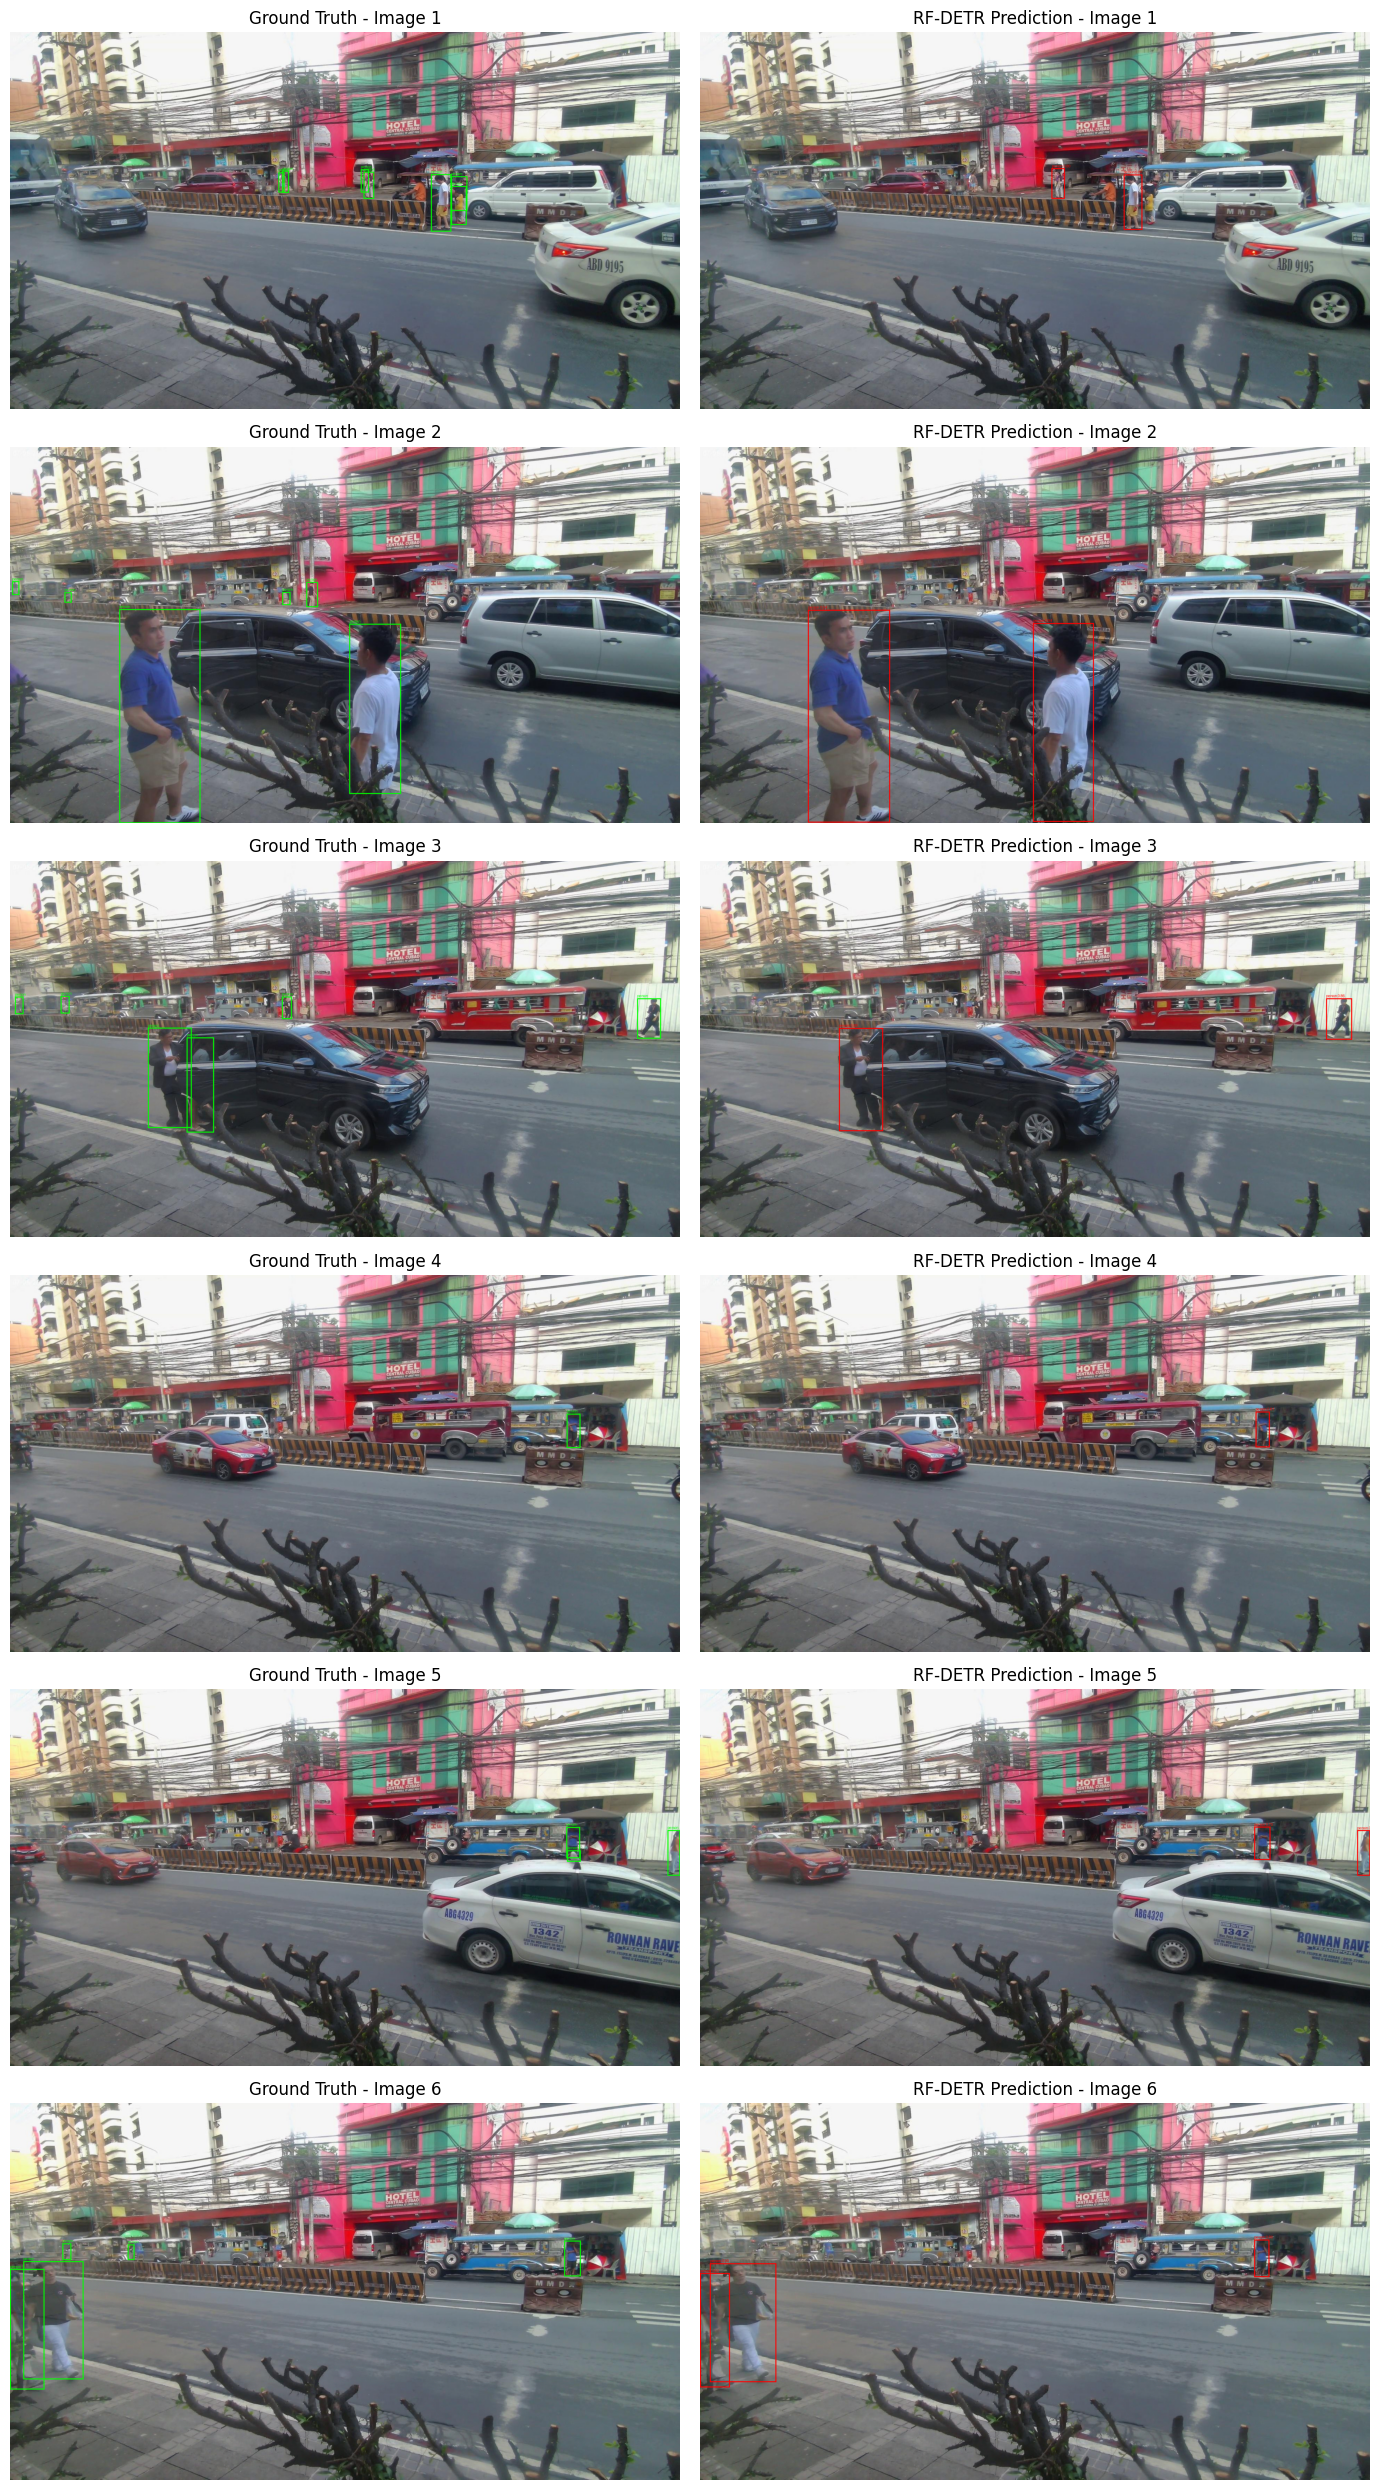

Saved visualization: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/CO2_2_RF_DETR/evaluation_results/RFDETR_Test_Predictions.png
RF-DETR prediction visualization: COMPLETE


In [16]:
# CODE CELL 16: VISUALIZE RF-DETR PEDESTRIAN PREDICTIONS

# Import NumPy to select representative test images at evenly spaced positions.
# This provides reproducible image selection without manually choosing favorable results.
import numpy as np

# Import PIL utilities to load images and draw bounding boxes.
# These utilities allow ground-truth labels and model predictions to be visualized clearly.
from PIL import Image, ImageDraw

# Import Matplotlib for displaying and saving prediction comparison figures.
# The saved visualization will provide evidence for the final project report.
import matplotlib.pyplot as plt

# Define the test image directory and its corresponding YOLO annotation directory.
# These directories contain the independent test images and validated pedestrian bounding boxes.
TEST_IMAGES_DIR = CHRONOLOGICAL_DIR / "test" / "images"
TEST_LABELS_DIR = CHRONOLOGICAL_DIR / "test" / "labels"

# Create a dedicated directory for the CO2.2 evaluation visualizations.
# This keeps the generated outputs separate from the previous computer vision activities.
VISUALIZATION_DIR = DATASET_ROOT / "CO2_2_RF_DETR" / "evaluation_results"
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

# Collect the available test images in a consistent alphabetical order.
# This allows the same images to be selected whenever the visualization cell is rerun.
test_image_files = sorted(
    file for file in TEST_IMAGES_DIR.iterdir()
    if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
)

# Confirm that the expected independent test images are available.
# This prevents the visualization from running on an empty or incorrect dataset directory.
assert len(test_image_files) == 130, "Unexpected number of test images."

# Select six evenly spaced images from the test dataset.
# This creates a reproducible qualitative sample without evaluating only handpicked successful predictions.
selected_indices = np.linspace(0, len(test_image_files) - 1, 6, dtype=int)
selected_images = [test_image_files[index] for index in selected_indices]

# Create a figure with ground-truth images on the left and predictions on the right.
# Each row compares the same image using its original annotations and the trained model's output.
fig, axes = plt.subplots(6, 2, figsize=(14, 25))

# Display the evaluation procedure's confidence threshold.
# A threshold of 0.50 is used here for visualization and may differ from the F1-sweep operating point.
CONFIDENCE_THRESHOLD = 0.50

# Process each selected test image individually.
# This produces matching ground-truth and prediction illustrations for all six examples.
for row_index, image_path in enumerate(selected_images):

    # Load the selected image and convert it into RGB format.
    # RGB conversion provides the image representation expected by the RF-DETR prediction interface.
    image = Image.open(image_path).convert("RGB")

    # Create independent copies for displaying ground truth and model predictions.
    # This ensures that drawing one set of bounding boxes does not affect the other visualization.
    ground_truth_image = image.copy()
    prediction_image = image.copy()

    # Retrieve the image dimensions for converting normalized YOLO coordinates.
    # Original image dimensions are needed to draw annotations at their correct pixel positions.
    image_width, image_height = image.size

    # Create drawing contexts for the ground-truth and prediction images.
    # These contexts allow bounding boxes and text labels to be placed on each image.
    ground_truth_draw = ImageDraw.Draw(ground_truth_image)
    prediction_draw = ImageDraw.Draw(prediction_image)

    # Locate the YOLO annotation file corresponding to the selected test image.
    # This file contains normalized ground-truth pedestrian bounding-box coordinates.
    label_path = TEST_LABELS_DIR / f"{image_path.stem}.txt"

    # Read each annotated pedestrian from the corresponding ground-truth file.
    # The annotations contain the class identifier and normalized bounding-box center, width, and height.
    for line in label_path.read_text(encoding="utf-8").splitlines():

        # Ignore empty annotation lines before parsing the coordinates.
        # This allows images without annotated pedestrians to be processed safely.
        if not line.strip():
            continue

        # Extract the class identifier and normalized YOLO bounding-box values.
        # The coordinates are converted from their stored text representation into numerical values.
        class_id, x, y, w, h = map(float, line.split())

        # Convert the normalized YOLO bounding box into absolute corner coordinates.
        # Pixel coordinates are required to draw the actual pedestrian box on the original image.
        x1 = (x - w / 2) * image_width
        y1 = (y - h / 2) * image_height
        x2 = (x + w / 2) * image_width
        y2 = (y + h / 2) * image_height

        # Draw the ground-truth pedestrian bounding box and class label.
        # The green outline identifies the annotated pedestrian location used as the reference.
        ground_truth_draw.rectangle([x1, y1, x2, y2], outline="lime", width=3)
        ground_truth_draw.text((x1, max(0, y1 - 13)), "person", fill="lime")

    # Generate pedestrian predictions using the trained RF-DETR Nano checkpoint.
    # Only detections meeting the selected confidence threshold are included in the visualization.
    detections = EVALUATION_MODEL.predict(
        image,
        threshold=CONFIDENCE_THRESHOLD
    )

    # Iterate through the predicted bounding boxes and confidence values.
    # The RF-DETR prediction interface returns absolute box coordinates in xyxy format.
    for box, confidence in zip(detections.xyxy, detections.confidence):

        # Convert the prediction coordinates into standard Python numerical values.
        # These coordinates identify the predicted pedestrian boundaries within the original image.
        x1, y1, x2, y2 = map(float, box)

        # Draw the predicted bounding box and its associated confidence score.
        # The red outline distinguishes model predictions from green ground-truth annotations.
        prediction_draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
        prediction_draw.text(
            (x1, max(0, y1 - 13)),
            f"person {confidence:.2f}",
            fill="red"
        )

    # Display the ground-truth image and hide its axis markings.
    # This provides a clear reference for comparing annotated pedestrians against model detections.
    axes[row_index, 0].imshow(ground_truth_image)
    axes[row_index, 0].set_title(f"Ground Truth - Image {row_index + 1}")
    axes[row_index, 0].axis("off")

    # Display the corresponding RF-DETR prediction and hide its axis markings.
    # This places the model's detections directly beside the ground-truth reference.
    axes[row_index, 1].imshow(prediction_image)
    axes[row_index, 1].set_title(f"RF-DETR Prediction - Image {row_index + 1}")
    axes[row_index, 1].axis("off")

# Adjust the figure layout to prevent titles and images from overlapping.
# This improves readability when the figure is inserted into the final PDF report.
plt.tight_layout()

# Define the file path used to preserve the comparison visualization.
# Saving to Google Drive ensures the figure remains available after the Colab session ends.
VISUALIZATION_PATH = VISUALIZATION_DIR / "RFDETR_Test_Predictions.png"

# Save the comparison figure as a high-resolution PNG image.
# The generated file can be included directly in the Results and Discussion section.
plt.savefig(VISUALIZATION_PATH, dpi=200, bbox_inches="tight")

# Display the comparison figure inside the Colab notebook.
# This allows visual inspection of pedestrian detection strengths and weaknesses.
plt.show()

# Close the Matplotlib figure after displaying and saving it.
# This releases temporary figure resources without deleting the saved visualization.
plt.close(fig)

# Display the saved visualization location and completion message.
# These details confirm that the required prediction comparison artifact was generated.
print("Saved visualization:", VISUALIZATION_PATH)
print("RF-DETR prediction visualization: COMPLETE")

### 4.3 Intersection over Union and Classification Accuracy Evaluation

This step calculates the Intersection over Union (IoU) between predicted pedestrian bounding boxes and ground-truth annotations across the independent test dataset. Hungarian matching is applied to establish one-to-one correspondence between detections and annotated objects using an IoU threshold of 0.50.

The evaluation calculates true positives, false positives, false negatives, mean matched IoU, and classification accuracy among matched detections. Since the dataset contains only the person class, classification accuracy is interpreted alongside precision and recall rather than as a standalone measure of detection quality.

In [17]:
# CODE CELL 17: CALCULATE IOU AND MATCHED CLASSIFICATION ACCURACY

# Import the Hungarian assignment algorithm from SciPy.
# This algorithm establishes one-to-one matching between predicted boxes and ground-truth boxes.
from scipy.optimize import linear_sum_assignment

# Import JSON to save the calculated evaluation results.
# Saving these measurements provides reproducible numerical evidence for the final report.
import json

# Define the confidence and IoU thresholds for fixed-threshold evaluation.
# These values are used consistently across all 130 independent test images.
EVAL_CONFIDENCE = 0.50
EVAL_IOU = 0.50

# Define a function to calculate IoU between two bounding boxes.
# Both boxes must use the absolute xyxy coordinate format.
def calculate_iou(box_a, box_b):

    # Calculate the overlapping rectangle's corner coordinates.
    # The intersection is determined using the maximum starting coordinates and minimum ending coordinates.
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    # Calculate the area shared by the two bounding boxes.
    # Negative overlap dimensions are treated as zero to represent non-overlapping boxes.
    intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)

    # Calculate the area of each bounding box individually.
    # The area is obtained by multiplying the box width by its height.
    area_a = max(0.0, box_a[2] - box_a[0]) * max(0.0, box_a[3] - box_a[1])
    area_b = max(0.0, box_b[2] - box_b[0]) * max(0.0, box_b[3] - box_b[1])

    # Calculate the union area and return the intersection divided by the union.
    # A zero union returns zero to prevent division errors.
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

# Initialize counters for the complete test-set evaluation.
# These values accumulate detection and classification statistics across all test images.
tp = 0
fp = 0
fn = 0
correct_classes = 0
matched_count = 0
matched_ious = []

# Display the evaluation heading and selected thresholds.
# This documents the conditions used for calculating the additional detection metrics.
print("CO2.2 - IOU AND CLASSIFICATION ACCURACY EVALUATION")
print("=" * 70)
print("Confidence threshold:", EVAL_CONFIDENCE)
print("IoU threshold:", EVAL_IOU)
print("Test images:", len(test_image_files))

# Process every image in the independent test dataset.
# No training or modification of the previously saved annotations occurs during this evaluation.
for image_path in test_image_files:

    # Load the original test image and identify its dimensions.
    # These dimensions are required to convert YOLO ground-truth annotations into pixel coordinates.
    with Image.open(image_path) as source:
        image = source.convert("RGB")
    image_width, image_height = image.size

    # Identify the annotation file corresponding to the current image.
    # The original chronological test labels provide the reference bounding boxes.
    label_path = TEST_LABELS_DIR / f"{image_path.stem}.txt"

    # Initialize the ground-truth bounding-box and class collections.
    # Each annotation will be converted into absolute coordinates for IoU evaluation.
    gt_boxes = []
    gt_classes = []

    # Read the annotation file and process each annotated pedestrian.
    # Empty annotation files are supported because some test images may contain no labeled objects.
    for line in label_path.read_text(encoding="utf-8").splitlines():

        # Skip empty lines to avoid parsing invalid annotation entries.
        # Only lines containing the expected YOLO detection values are processed.
        if not line.strip():
            continue

        # Extract the class identifier and normalized bounding-box values.
        # The chronological dataset contains a single person class with identifier zero.
        class_id, x, y, w, h = map(float, line.split())

        # Convert the normalized annotation into absolute xyxy coordinates.
        # This allows direct comparison with RF-DETR's prediction coordinates.
        gt_boxes.append([
            (x - w / 2) * image_width,
            (y - h / 2) * image_height,
            (x + w / 2) * image_width,
            (y + h / 2) * image_height
        ])

        # Store the corresponding ground-truth classification label.
        # This label will be compared with the predicted class after bounding-box matching.
        gt_classes.append(int(class_id))

    # Generate predictions using the previously trained RF-DETR Nano model.
    # Predictions below the selected confidence threshold are excluded from this fixed-threshold evaluation.
    predictions = EVALUATION_MODEL.predict(
        image,
        threshold=EVAL_CONFIDENCE
    )

    # Convert the predicted bounding boxes and class identifiers into standard NumPy arrays.
    # RF-DETR returns xyxy boxes and zero-based class IDs for the fine-tuned detection model.
    pred_boxes = np.asarray(predictions.xyxy).reshape(-1, 4)
    pred_classes = np.asarray(predictions.class_id).astype(int)

    # Construct the pairwise IoU matrix for the current image.
    # Each matrix entry represents the overlap between one ground-truth box and one predicted box.
    iou_matrix = np.array([
        [calculate_iou(gt_box, pred_box) for pred_box in pred_boxes]
        for gt_box in gt_boxes
    ], dtype=float).reshape(len(gt_boxes), len(pred_boxes))

    # Initialize the number of valid matches for the current image.
    # This count determines which predictions and ground-truth boxes remain unmatched.
    image_matches = 0

    # Perform Hungarian matching only when both annotations and predictions are present.
    # Images without predictions or ground-truth boxes are handled directly through false-positive and false-negative counts.
    if len(gt_boxes) > 0 and len(pred_boxes) > 0:

        # Build a matching score that prioritizes IoU-qualified pairs.
        # The large constant rewards valid matches first, while IoU breaks ties between assignments.
        matching_score = np.where(
            iou_matrix >= EVAL_IOU,
            1000.0 + iou_matrix,
            0.0
        )

        # Determine the optimal one-to-one assignment between ground truth and predictions.
        # Maximizing the matching score prioritizes the number of valid detections.
        matched_gt, matched_pred = linear_sum_assignment(
            matching_score,
            maximize=True
        )

        # Examine each assigned ground-truth and prediction pair.
        # Only matches meeting the specified IoU threshold count as valid detections.
        for gt_index, pred_index in zip(matched_gt, matched_pred):

            # Skip pairs whose IoU is below the required matching threshold.
            # Such assignments do not represent correct detections under this evaluation protocol.
            if iou_matrix[gt_index, pred_index] < EVAL_IOU:
                continue

            # Count the accepted one-to-one object match and record its IoU.
            # These results contribute to the overall true-positive count and mean matched IoU.
            image_matches += 1
            matched_count += 1
            matched_ious.append(float(iou_matrix[gt_index, pred_index]))

            # Compare the predicted class with the ground-truth class.
            # Correct classifications are counted only for bounding boxes that have already passed IoU matching.
            if pred_classes[pred_index] == gt_classes[gt_index]:
                correct_classes += 1

    # Update true positives using the number of accepted bounding-box matches.
    # Each accepted match corresponds to one detected ground-truth pedestrian.
    tp += image_matches

    # Count predictions not matched to ground-truth pedestrians as false positives.
    # This includes predictions that do not overlap sufficiently with any annotated object.
    fp += len(pred_boxes) - image_matches

    # Count ground-truth pedestrians without a qualifying prediction as false negatives.
    # These values represent missed detections at the specified confidence and IoU thresholds.
    fn += len(gt_boxes) - image_matches

# Calculate precision and recall using the accumulated detection counts.
# These scores reflect the fixed confidence and IoU thresholds rather than the official F1 sweep.
fixed_precision = tp / (tp + fp) if tp + fp > 0 else 0.0
fixed_recall = tp / (tp + fn) if tp + fn > 0 else 0.0

# Calculate classification accuracy among qualifying one-to-one matches.
# The single-class dataset limits the usefulness of this measure because all ground-truth objects are persons.
classification_accuracy = (
    correct_classes / matched_count if matched_count > 0 else None
)

# Calculate the average bounding-box IoU among accepted matches.
# This describes localization quality for successfully matched detections only.
mean_matched_iou = (
    float(np.mean(matched_ious)) if matched_ious else None
)

# Collect the calculated metrics and matching counts in a dictionary.
# This preserves the evaluation thresholds and numerical results for reporting.
ADDITIONAL_METRICS = {
    "confidence_threshold": EVAL_CONFIDENCE,
    "iou_threshold": EVAL_IOU,
    "true_positives": tp,
    "false_positives": fp,
    "false_negatives": fn,
    "classification_accuracy": classification_accuracy,
    "mean_matched_iou": mean_matched_iou,
    "fixed_threshold_precision": fixed_precision,
    "fixed_threshold_recall": fixed_recall
}

# Display the completed test-set evaluation results.
# These statistics supplement the official RF-DETR mAP and recall measurements.
print("\nFINAL FIXED-THRESHOLD EVALUATION")
for metric, value in ADDITIONAL_METRICS.items():
    print(f"{metric}: {value}")

# Define a JSON output file for the additional evaluation measurements.
# This file will provide a compact numerical record for the final project report.
ADDITIONAL_METRICS_PATH = VISUALIZATION_DIR / "RFDETR_Additional_Test_Metrics.json"

# Save the evaluation results in JSON format.
# Writing the metric summary preserves the results without overwriting the trained model or dataset.
with open(ADDITIONAL_METRICS_PATH, "w", encoding="utf-8") as file:
    json.dump(ADDITIONAL_METRICS, file, indent=4)

# Display the saved metrics location and completion status.
# This confirms that the calculations finished and the evaluation summary was preserved.
print("\nSaved metrics:", ADDITIONAL_METRICS_PATH)
print("IoU and classification accuracy evaluation: COMPLETE")

CO2.2 - IOU AND CLASSIFICATION ACCURACY EVALUATION
Confidence threshold: 0.5
IoU threshold: 0.5
Test images: 130

FINAL FIXED-THRESHOLD EVALUATION
confidence_threshold: 0.5
iou_threshold: 0.5
true_positives: 290
false_positives: 24
false_negatives: 306
classification_accuracy: 1.0
mean_matched_iou: 0.8299656403475795
fixed_threshold_precision: 0.9235668789808917
fixed_threshold_recall: 0.4865771812080537

Saved metrics: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/CO2_2_RF_DETR/evaluation_results/RFDETR_Additional_Test_Metrics.json
IoU and classification accuracy evaluation: COMPLETE


### 5.1 Training Metrics Inspection

This step examines the training metrics recorded during the 20-epoch RF-DETR Nano fine-tuning experiment. The saved metrics are reviewed to identify available training losses, validation performance measurements, and learning-rate information.

The inspection establishes which numerical results can be used to analyze model optimization and training behavior in the final project report. No additional training or evaluation is performed during this step.

In [18]:
# CODE CELL 18: INSPECT RF-DETR TRAINING METRICS

# Import pandas to examine the saved RF-DETR training metrics.
# This library allows us to inspect the recorded results without rerunning model training.
import pandas as pd

# Define the location of the metrics CSV generated during training.
# The file contains available training and validation measurements from the completed experiment.
METRICS_CSV_PATH = RFDETR_OUTPUT_DIR / "metrics.csv"

# Verify that the expected training metrics file exists.
# This prevents attempting to analyze a missing or incorrectly located CSV file.
assert METRICS_CSV_PATH.is_file(), "Training metrics CSV was not found."

# Load the training metrics into a pandas DataFrame.
# This provides access to the recorded epoch information, loss values, and evaluation measurements.
TRAINING_METRICS_DF = pd.read_csv(METRICS_CSV_PATH)

# Display the heading for the saved training metrics inspection.
# This distinguishes the current analysis from the independent test-set evaluation.
print("CO2.2 - RF-DETR TRAINING METRICS INSPECTION")
print("=" * 70)

# Display the CSV file location and number of recorded rows.
# The row count may exceed the number of epochs because different metrics can be logged separately.
print("Metrics file:", METRICS_CSV_PATH)
print("Recorded rows:", len(TRAINING_METRICS_DF))

# Display the names of every recorded metric.
# This identifies which training and validation measurements are available for further analysis.
print("\nAVAILABLE METRIC COLUMNS:")
for column in TRAINING_METRICS_DF.columns:
    print("-", column)

# Display the first five rows of the recorded training metrics.
# These rows help identify the structure of the CSV and how the metrics were logged.
print("\nFIRST FIVE RECORDED ROWS:")
print(TRAINING_METRICS_DF.head(5).to_string(index=False))

# Display the final five rows of the recorded training metrics.
# These rows help identify the measurements available near the end of the training experiment.
print("\nLAST FIVE RECORDED ROWS:")
print(TRAINING_METRICS_DF.tail(5).to_string(index=False))

# Identify columns related to training losses and validation evaluation metrics.
# These measurements are the most relevant for the required discussion of training and optimization.
RELEVANT_COLUMNS = [
    column for column in TRAINING_METRICS_DF.columns
    if any(keyword in column.lower() for keyword in ["epoch", "loss", "map", "lr"])
]

# Display the list of relevant training and validation metrics.
# This prepares us to select appropriate measurements for the final results analysis.
print("\nRELEVANT TRAINING AND VALIDATION COLUMNS:")
for column in RELEVANT_COLUMNS:
    print("-", column)

# Confirm completion of the training metrics inspection.
# No model checkpoints, datasets, or recorded metric values are modified.
print("\nTraining metrics inspection: COMPLETE")

CO2.2 - RF-DETR TRAINING METRICS INSPECTION
Metrics file: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/CO2_2_RF_DETR/training_results/metrics.csv
Recorded rows: 72

AVAILABLE METRIC COLUMNS:
- epoch
- step
- train/cardinality_error
- train/cardinality_error_0
- train/cardinality_error_enc
- train/class_error
- train/loss
- train/loss_bbox
- train/loss_bbox_aux
- train/loss_ce
- train/loss_ce_aux
- train/loss_giou
- train/loss_giou_aux
- train/lr
- train/lr_max
- train/lr_min
- val/F1
- val/ema_mAP_50
- val/ema_mAP_50_95
- val/ema_mAP_75
- val/ema_mAR
- val/mAP_50
- val/mAP_50_95
- val/mAP_75
- val/mAR
- val/precision
- val/recall

FIRST FIVE RECORDED ROWS:
 epoch  step  train/cardinality_error  train/cardinality_error_0  train/cardinality_error_enc  train/class_error  train/loss  train/loss_bbox  train/loss_bbox_aux  train/loss_ce  train/loss_ce_aux  train/loss_giou  train/loss_giou_aux  train/lr  train/lr_max  train/lr_min   val/F1  val/ema_mAP_50  val/ema_mAP_50_95  val/ema_mAP_

### 5.2 Training Loss and Validation mAP Visualization

This step visualizes the training and validation performance of the RF-DETR Nano model using the metrics recorded during the completed 20-epoch experiment. The training loss curve illustrates how the model's optimization objective changed, while the validation mAP curves show the development of pedestrian detection performance across epochs.

Since the training CSV records different metrics in separate rows, the available measurements are first organized by epoch before plotting. The resulting graphs are saved to Google Drive for inclusion in the Training and Optimization and Results and Discussion sections of the final project report.

CO2.2 - RF-DETR TRAINING PERFORMANCE VISUALIZATION
 epoch_number  train/loss  val/mAP_50  val/mAP_50_95
            1    5.718284    0.402976       0.226362
            2    5.323857    0.539356       0.274075
            3    5.115194    0.552788       0.289727
            4    4.890808    0.582168       0.316969
            5    4.886418    0.595266       0.292302


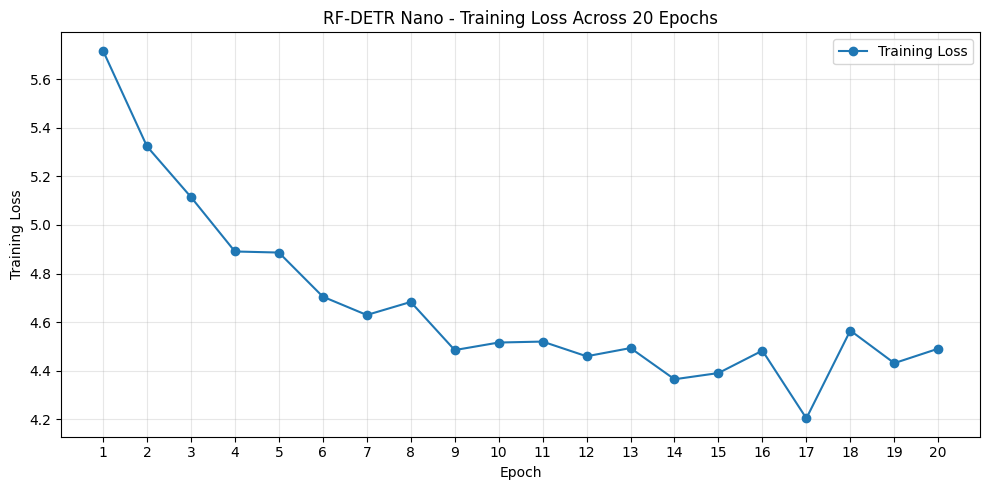

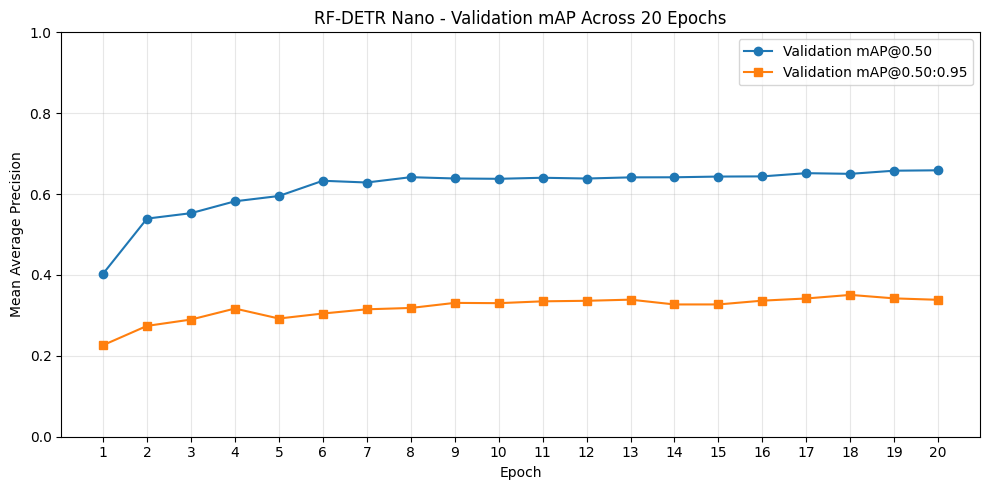


TRAINING LOSS SUMMARY
Initial loss: 5.7183
Final loss: 4.4903

VALIDATION mAP SUMMARY
Initial mAP@0.50: 0.403
Final mAP@0.50: 0.6588
Initial mAP@0.50:0.95: 0.2264
Final mAP@0.50:0.95: 0.3386

SAVED PERFORMANCE GRAPHS
Training Loss: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/CO2_2_RF_DETR/evaluation_results/RFDETR_Training_Loss.png
Validation mAP: /content/drive/MyDrive/CO1_1_Pedestrian_Detection/CO2_2_RF_DETR/evaluation_results/RFDETR_Validation_mAP.png

RF-DETR training performance visualization: COMPLETE


In [19]:
# CODE CELL 19: GENERATE RF-DETR TRAINING PERFORMANCE GRAPHS

# Define the training and validation metrics required for the two performance graphs.
# These columns were confirmed to exist in the metrics.csv file during Code Cell 18.
PLOT_COLUMNS = [
    "train/loss",
    "val/mAP_50",
    "val/mAP_50_95"
]

# Verify that the required epoch and performance columns are available.
# This prevents generating misleading graphs when expected training measurements are missing.
assert all(
    column in TRAINING_METRICS_DF.columns
    for column in ["epoch"] + PLOT_COLUMNS
), "Required training metrics are missing."

# Organize the recorded measurements by their corresponding training epoch.
# RF-DETR logs different metrics in separate rows, so the final nonempty value for each metric is selected.
EPOCH_METRICS = (
    TRAINING_METRICS_DF
    .groupby("epoch")[PLOT_COLUMNS]
    .agg(lambda values: values.dropna().iloc[-1] if values.notna().any() else float("nan"))
    .reset_index()
)

# Convert the zero-based epoch identifiers into human-readable epoch numbers.
# This displays the completed training experiment using epochs 1 through 20.
EPOCH_METRICS["epoch_number"] = EPOCH_METRICS["epoch"] + 1

# Verify that the expected 20 training epochs are represented in the organized measurements.
# A missing epoch would require inspecting the saved CSV before interpreting the training curves.
assert EPOCH_METRICS["epoch_number"].tolist() == list(range(1, 21)), (
    "The training log does not contain all 20 expected epochs."
)

# Confirm that the required training and validation measurements are available for every epoch.
# This avoids silently plotting incomplete performance curves.
assert EPOCH_METRICS[PLOT_COLUMNS].notna().all().all(), (
    "One or more epochs have missing training loss or validation mAP values."
)

# Display a heading and the first few organized training records.
# This confirms that the epoch measurements were correctly combined before graph generation.
print("CO2.2 - RF-DETR TRAINING PERFORMANCE VISUALIZATION")
print("=" * 70)
print(EPOCH_METRICS[["epoch_number"] + PLOT_COLUMNS].head().to_string(index=False))

# Create a figure showing total training loss across the completed epochs.
# The plotted values come directly from the RF-DETR training log rather than estimated results.
plt.figure(figsize=(10, 5))
plt.plot(
    EPOCH_METRICS["epoch_number"],
    EPOCH_METRICS["train/loss"],
    marker="o",
    label="Training Loss"
)

# Add descriptive labels, a title, and a grid to the training loss graph.
# These elements make the figure understandable when included independently in the project report.
plt.title("RF-DETR Nano - Training Loss Across 20 Epochs")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.xticks(range(1, 21))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Define the output location for the training loss figure.
# The file is stored in the existing CO2.2 evaluation results directory.
TRAINING_LOSS_GRAPH = VISUALIZATION_DIR / "RFDETR_Training_Loss.png"

# Save and display the completed training loss curve.
# The figure is exported as a high-resolution image suitable for the final report.
plt.savefig(TRAINING_LOSS_GRAPH, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# Create a separate figure showing the two validation mAP measurements.
# mAP@0.50 and mAP@0.50:0.95 provide complementary measures of pedestrian detection performance.
plt.figure(figsize=(10, 5))
plt.plot(
    EPOCH_METRICS["epoch_number"],
    EPOCH_METRICS["val/mAP_50"],
    marker="o",
    label="Validation mAP@0.50"
)
plt.plot(
    EPOCH_METRICS["epoch_number"],
    EPOCH_METRICS["val/mAP_50_95"],
    marker="s",
    label="Validation mAP@0.50:0.95"
)

# Add labels and a legend to distinguish the two validation measurements.
# The graph illustrates how detection quality changed during the 20-epoch fine-tuning process.
plt.title("RF-DETR Nano - Validation mAP Across 20 Epochs")
plt.xlabel("Epoch")
plt.ylabel("Mean Average Precision")
plt.xticks(range(1, 21))
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Define the output location for the validation mAP figure.
# Saving it separately makes the graph easier to insert into the report.
VALIDATION_MAP_GRAPH = VISUALIZATION_DIR / "RFDETR_Validation_mAP.png"

# Save and display the completed validation mAP graph.
# This preserves the measured detection performance for subsequent discussion and documentation.
plt.savefig(VALIDATION_MAP_GRAPH, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# Display the first and final recorded training loss measurements.
# These values provide a concise numerical summary of the model's optimization progress.
print("\nTRAINING LOSS SUMMARY")
print("Initial loss:", round(float(EPOCH_METRICS["train/loss"].iloc[0]), 4))
print("Final loss:", round(float(EPOCH_METRICS["train/loss"].iloc[-1]), 4))

# Display the first and final validation mAP measurements.
# These values summarize the model's detection performance changes during training.
print("\nVALIDATION mAP SUMMARY")
print("Initial mAP@0.50:", round(float(EPOCH_METRICS["val/mAP_50"].iloc[0]), 4))
print("Final mAP@0.50:", round(float(EPOCH_METRICS["val/mAP_50"].iloc[-1]), 4))
print("Initial mAP@0.50:0.95:", round(float(EPOCH_METRICS["val/mAP_50_95"].iloc[0]), 4))
print("Final mAP@0.50:0.95:", round(float(EPOCH_METRICS["val/mAP_50_95"].iloc[-1]), 4))

# Display the saved file locations and the completion status.
# Both figures will be available for the training analysis section of the final PDF report.
print("\nSAVED PERFORMANCE GRAPHS")
print("Training Loss:", TRAINING_LOSS_GRAPH)
print("Validation mAP:", VALIDATION_MAP_GRAPH)
print("\nRF-DETR training performance visualization: COMPLETE")